# A/B Testing & Impact Measurement on Olist delivery data

**Question:** if operations launched an initiative to cut late deliveries, how would we prove it worked?

This notebook is a learning companion to the main project. It runs on the **aggregate tables already in
`reports/tables/`**, so it needs neither the raw Olist CSVs nor the DuckDB model.

| Part | What it covers | Data |
|---|---|---|
| 1 | Designing an experiment: metric, MDE, power, sample size, duration | Real baselines and volumes |
| 2 | Analysing an experiment: SRM check, two-proportion z-test, confidence interval, decision | **Simulated** (seeded) |
| 3 | Two pitfalls: peeking and multiple metrics | **Simulated** A/A tests |
| 4 | Why observational comparisons and naive pre/post are not experiments | Real Olist aggregates |
| 5 | Difference-in-differences when you cannot randomise | **Illustrative** numbers |
| 6 | Cross-check of the hand-written tests against `statsmodels` | Same inputs |

Nothing in Parts 2, 3 and 5 is an Olist result: no initiative was ever run on this data. Part 4 stays
observational, consistent with the rest of the project.

In [1]:
from __future__ import annotations

import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

ROOT = Path.cwd() if (Path.cwd() / "reports").exists() else Path.cwd().parent
TABLES = ROOT / "reports" / "tables"
FIGS = ROOT / "reports" / "figures"
ALPHA, POWER = 0.05, 0.80
SEED = 20261031

## Helper functions (written by hand so every step is visible)

**Two-proportion z-test.** Under H0 both groups share one late rate, so the standard error uses the
pooled rate $\hat p = (x_1+x_2)/(n_1+n_2)$:

$$z = \frac{\hat p_1 - \hat p_2}{\sqrt{\hat p(1-\hat p)(1/n_1 + 1/n_2)}}$$

**Confidence interval for the difference.** No H0 is assumed here, so each group keeps its own variance
(unpooled Wald interval): $(\hat p_1-\hat p_2) \pm z_{0.975}\sqrt{\hat p_1(1-\hat p_1)/n_1 + \hat p_2(1-\hat p_2)/n_2}$.

**Sample size per arm** to detect $p_1$ vs $p_2$ with significance $\alpha$ (two-sided) and power $1-\beta$:

$$n = \frac{\left(z_{1-\alpha/2}\sqrt{2\bar p(1-\bar p)} + z_{1-\beta}\sqrt{p_1(1-p_1)+p_2(1-p_2)}\right)^2}{(p_1-p_2)^2}$$

In [2]:
def ztest_2prop(x1: int, n1: int, x2: int, n2: int) -> tuple[float, float]:
    """Two-sided pooled two-proportion z-test. Returns (z, p_value)."""
    p1, p2 = x1 / n1, x2 / n2
    pooled = (x1 + x2) / (n1 + n2)
    se = math.sqrt(pooled * (1 - pooled) * (1 / n1 + 1 / n2))
    z = (p1 - p2) / se
    return z, 2 * stats.norm.sf(abs(z))


def diff_ci(x1: int, n1: int, x2: int, n2: int, alpha: float = ALPHA) -> tuple[float, float, float]:
    """Unpooled Wald CI for p1 - p2. Returns (diff, lo, hi)."""
    p1, p2 = x1 / n1, x2 / n2
    se = math.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    z = stats.norm.ppf(1 - alpha / 2)
    d = p1 - p2
    return d, d - z * se, d + z * se


def n_per_arm(p1: float, p2: float, alpha: float = ALPHA, power: float = POWER) -> int:
    """Orders needed in EACH arm to detect p1 vs p2 (two-sided)."""
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    pbar = (p1 + p2) / 2
    num = za * math.sqrt(2 * pbar * (1 - pbar)) + zb * math.sqrt(p1 * (1 - p1) + p2 * (1 - p2))
    return math.ceil(num**2 / (p1 - p2) ** 2)


def srm_pvalue(n_a: int, n_b: int, expected_share_a: float = 0.5) -> float:
    """Sample-ratio-mismatch check: chi-square goodness of fit against the planned split."""
    total = n_a + n_b
    exp = [total * expected_share_a, total * (1 - expected_share_a)]
    return stats.chisquare([n_a, n_b], f_exp=exp).pvalue

## Part 1: Designing the experiment

**Hypothetical initiative.** Operations proposes a faster seller-to-carrier handoff for **cross-state
shipments** (the segment with the higher late rate in this project). Orders would be randomised 50/50 at
the order level into *control* (current process) and *treatment* (new handoff).

Before launch, write down:
- **Primary metric:** late-delivery rate (delivered after the promised date), the project's KPI.
- **Guardrail metrics:** median lead time and the 1-2 star review share must not get worse.
- **Minimum detectable effect (MDE):** the smallest improvement worth acting on. Here, a 15% relative cut.
- **alpha = 0.05, power = 0.80**, two-sided, and a fixed sample size (no stopping early, see Part 3).

The baseline and volumes below come from `geo_shipment_type.csv` and `geo_lanes.csv`.

In [3]:
ship = pd.read_csv(TABLES / "geo_shipment_type.csv").set_index("label")
lanes = pd.read_csv(TABLES / "geo_lanes.csv").set_index("lane")
monthly = pd.read_csv(TABLES / "delivery_monthly.csv", parse_dates=["purchase_month"])
N_MONTHS = monthly["purchase_month"].nunique()

segments = {
    "All cross-state": (ship.loc["Cross-state", "late_rate"], ship.loc["Cross-state", "n_delivered"]),
    "SP>RJ lane only": (lanes.loc["SP>RJ", "late_rate"], lanes.loc["SP>RJ", "n_delivered"]),
}

rows = []
for seg, (base, n_total) in segments.items():
    per_month = n_total / N_MONTHS
    for rel in (0.10, 0.15, 0.20, 0.30):
        target = base * (1 - rel)
        n = n_per_arm(base, target)
        rows.append({
            "segment": seg, "baseline_late_rate": base, "relative_MDE": rel, "target_late_rate": target,
            "n_per_arm": n, "orders_per_month": round(per_month), "months_needed": 2 * n / per_month,
        })
design = pd.DataFrame(rows)
print(design.to_string(index=False, formatters={
    "baseline_late_rate": "{:.2%}".format, "target_late_rate": "{:.2%}".format, "relative_MDE": "{:.0%}".format,
    "n_per_arm": "{:,}".format, "orders_per_month": "{:,}".format, "months_needed": "{:.1f}".format}))

        segment baseline_late_rate relative_MDE target_late_rate n_per_arm orders_per_month months_needed
All cross-state              8.16%          10%            7.34%    16,861            3,039          11.1
All cross-state              8.16%          15%            6.93%     7,312            3,039           4.8
All cross-state              8.16%          20%            6.53%     4,011            3,039           2.6
All cross-state              8.16%          30%            5.71%     1,690            3,039           1.1
SP>RJ lane only             14.28%          10%           12.85%     9,024              402          44.9
SP>RJ lane only             14.28%          15%           12.14%     3,921              402          19.5
SP>RJ lane only             14.28%          20%           11.43%     2,154              402          10.7
SP>RJ lane only             14.28%          30%           10.00%       911              402           4.5


**How to read this (the interview talking point):**
- Smaller effects need far more data: halving the MDE roughly **quadruples** the sample size.
- Narrowing to one lane raises the baseline (easier to detect) but cuts volume so much that the test takes
  longer. Choosing the population is a trade-off between relevance and speed.
- If the test would take longer than the business can wait, the options are: accept a larger MDE, widen the
  population, use a more sensitive metric, or reduce variance (e.g. stratify by lane).
- Duration should also cover **full weekly cycles** and avoid starting inside a sale peak.

## Part 2: Analysing the experiment (SIMULATED)

We simulate the cross-state test planned above at a 15% MDE, assuming the initiative truly works. The true
rates are chosen by us, so this shows the *mechanics* of the analysis, not an Olist finding.

In [4]:
rng = np.random.default_rng(SEED)
base = ship.loc["Cross-state", "late_rate"]
true_control, true_treat = base, base * 0.85
n_planned = n_per_arm(true_control, true_treat)

# Randomise 2 * n_planned orders 50/50 (a coin flip per order, so the split is not exactly equal)
assign = rng.random(2 * n_planned) < 0.5
n_t, n_c = int(assign.sum()), int((~assign).sum())
late_t = int(rng.binomial(n_t, true_treat))
late_c = int(rng.binomial(n_c, true_control))

print(f"Arms: treatment n={n_t:,}, control n={n_c:,}")
print(f"Step 1 SRM check p-value: {srm_pvalue(n_t, n_c):.3f}  (p < 0.001 would mean the split is broken: stop)")

rate_t, rate_c = late_t / n_t, late_c / n_c
z, p = ztest_2prop(late_t, n_t, late_c, n_c)
d, lo, hi = diff_ci(late_t, n_t, late_c, n_c)
print(f"Step 2 late rate: treatment {rate_t:.2%} vs control {rate_c:.2%}")
print(f"Step 3 z = {z:.2f}, p = {p:.4f}")
print(f"Step 4 difference {d * 100:+.2f} pp (95% CI {lo * 100:+.2f} to {hi * 100:+.2f} pp); relative change {d / rate_c:+.1%}")
decision = "ship" if (p < ALPHA and hi < 0) else "do not ship / keep testing"
print(f"Step 5 decision against the pre-registered rule: {decision}")

Arms: treatment n=7,265, control n=7,359
Step 1 SRM check p-value: 0.437  (p < 0.001 would mean the split is broken: stop)
Step 2 late rate: treatment 7.06% vs control 8.25%
Step 3 z = -2.70, p = 0.0070
Step 4 difference -1.19 pp (95% CI -2.05 to -0.33 pp); relative change -14.4%
Step 5 decision against the pre-registered rule: ship


**Reporting it to stakeholders (one sentence each):**
1. *What happened:* late rate fell from X% to Y% (a Z-point drop, 95% CI A to B).
2. *How sure:* the interval excludes zero, so the drop is unlikely to be chance at the 5% level.
3. *So what:* translate into orders, e.g. "about N fewer late orders per month at current volume".
4. *Guardrails:* lead time and low-review share did not worsen (check them, they are part of the decision).

Note the p-value is **not** "the probability the initiative works". It is the probability of seeing a gap at
least this large if the initiative had no effect.

In [5]:
monthly_cross = ship.loc["Cross-state", "n_delivered"] / N_MONTHS
print(f"Impact in business terms: about {-d * monthly_cross:,.0f} fewer late cross-state orders per month "
      f"(range {-hi * monthly_cross:,.0f} to {-lo * monthly_cross:,.0f})")

Impact in business terms: about 36 fewer late cross-state orders per month (range 10 to 62)


## Part 3: Two pitfalls, shown by simulation

### 3a. Peeking
An **A/A test** gives both arms the same treatment, so every "significant" result is a false positive and
should happen 5% of the time. If we check the p-value 10 times during the test and stop at the first
p < 0.05, the false-positive rate rises well above 5%.

In [6]:
def aa_false_positive_rate(n_sims: int, n_final: int, looks: int, p: float, rng: np.random.Generator) -> tuple[float, float]:
    checkpoints = np.linspace(n_final / looks, n_final, looks).astype(int)
    fp_end = fp_peek = 0
    for _ in range(n_sims):
        a = rng.random(n_final) < p
        b = rng.random(n_final) < p
        ca, cb = np.cumsum(a), np.cumsum(b)
        pvals = [ztest_2prop(int(ca[k - 1]), k, int(cb[k - 1]), k)[1] for k in checkpoints]
        fp_end += pvals[-1] < ALPHA
        fp_peek += min(pvals) < ALPHA
    return fp_end / n_sims, fp_peek / n_sims


fp_end, fp_peek = aa_false_positive_rate(n_sims=1000, n_final=5000, looks=10, p=base, rng=np.random.default_rng(SEED))
print(f"A/A false-positive rate, one look at the end: {fp_end:.1%}")
print(f"A/A false-positive rate, stop at first of 10 looks with p<0.05: {fp_peek:.1%}")

A/A false-positive rate, one look at the end: 5.0%
A/A false-positive rate, stop at first of 10 looks with p<0.05: 19.5%


**Fix:** fix the sample size in advance and analyse once, or use a method built for repeated looks
(sequential testing / alpha spending). Dashboards can show progress, but the decision waits.

### 3b. Multiple metrics
Testing 10 independent metrics at alpha = 0.05 gives a $1-0.95^{10}$ chance of at least one false "win":

In [7]:
for k in (1, 5, 10, 20):
    print(f"{k:>2} metrics: P(at least one false positive) = {1 - (1 - ALPHA) ** k:.0%};"
          f"  Bonferroni per-metric alpha = {ALPHA / k:.4f}")

 1 metrics: P(at least one false positive) = 5%;  Bonferroni per-metric alpha = 0.0500
 5 metrics: P(at least one false positive) = 23%;  Bonferroni per-metric alpha = 0.0100
10 metrics: P(at least one false positive) = 40%;  Bonferroni per-metric alpha = 0.0050
20 metrics: P(at least one false positive) = 64%;  Bonferroni per-metric alpha = 0.0025


**Fix:** choose **one primary metric** before launch; treat the rest as guardrails or explore them with a
correction such as Bonferroni.

## Part 4: Real Olist data, and why it is not an experiment

### 4a. Same-state vs cross-state is significant, but it is not an A/B test
The z-test happily returns a tiny p-value. But orders were not randomised into cross-state shipping: cross-state
orders differ in destination, promised lead time and purchase month. The project's Mantel-Haenszel analysis
(`reports/geo_stats.json`) shows that adjusting for those strata **changes the risk ratio** from the crude
value, which is the signature of confounding.

In [8]:
import json

geo = json.loads((ROOT / "reports" / "geo_stats.json").read_text())["mh_cross_state"]
xs, ss = ship.loc["Cross-state"], ship.loc["Same-state"]
z, p = ztest_2prop(int(xs.n_late), int(xs.n_delivered), int(ss.n_late), int(ss.n_delivered))
d, lo, hi = diff_ci(int(xs.n_late), int(xs.n_delivered), int(ss.n_late), int(ss.n_delivered))
print(f"Cross-state {xs.late_rate:.2%} vs same-state {ss.late_rate:.2%}: z = {z:.1f}, p = {p:.1e}")
print(f"Difference {d * 100:+.2f} pp (95% CI {lo * 100:+.2f} to {hi * 100:+.2f} pp)")
print(f"Risk ratio crude {geo['rr_crude']:.2f} vs Mantel-Haenszel adjusted {geo['rr_mh']:.2f} "
      f"(95% CI {geo['rr_lo']:.2f} to {geo['rr_hi']:.2f})")

Cross-state 8.16% vs same-state 4.57%: z = 21.0, p = 5.1e-98
Difference +3.59 pp (95% CI +3.28 to +3.90 pp)
Risk ratio crude 1.79 vs Mantel-Haenszel adjusted 2.37 (95% CI 2.20 to 2.56)


A significant p-value answers "is this gap bigger than noise?", **not** "did shipping cross-state cause it?".
Randomisation is what lets an A/B test answer the second question.

### 4b. The naive pre/post trap
Suppose a manager says: *"We launched a new carrier process on 1 April 2018. Compare Feb-Mar with Apr-May."*
**No initiative was launched**: the dataset has none. Yet the comparison looks like a big win.

In [9]:
m = monthly.set_index("purchase_month")
pre = m.loc["2018-02-01":"2018-03-01"]
post = m.loc["2018-04-01":"2018-05-01"]
x_pre, n_pre = int(pre.n_late.sum()), int(pre.n_delivered.sum())
x_post, n_post = int(post.n_late.sum()), int(post.n_delivered.sum())
z, p = ztest_2prop(x_post, n_post, x_pre, n_pre)
print(f"'Before' (Feb-Mar 2018): {x_pre / n_pre:.2%} late on {n_pre:,} orders")
print(f"'After'  (Apr-May 2018): {x_post / n_post:.2%} late on {n_post:,} orders")
print(f"z = {z:.1f}, p = {p:.1e}  -> 'significant', yet nothing was launched")

'Before' (Feb-Mar 2018): 16.62% late on 13,558 orders
'After'  (Apr-May 2018): 5.53% late on 13,547 orders
z = -29.1, p = 3.5e-186  -> 'significant', yet nothing was launched


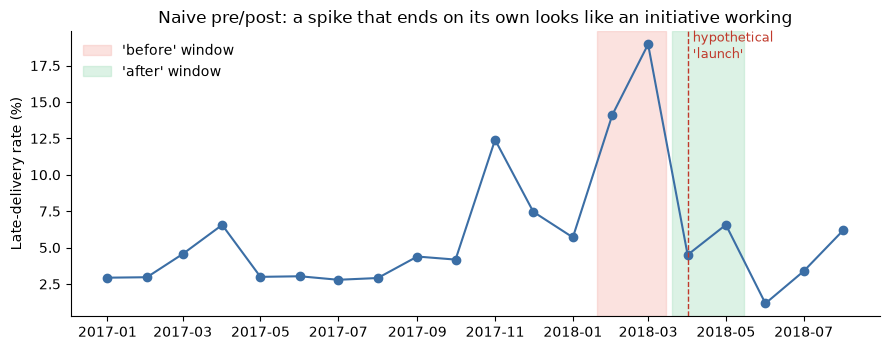

In [10]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(m.index, m.late_rate * 100, marker="o", color="#3b6ea5")
ax.axvline(pd.Timestamp("2018-04-01"), color="#c0392b", ls="--", lw=1)
ax.text(pd.Timestamp("2018-04-05"), m.late_rate.max() * 100 * 0.95, "hypothetical\n'launch'", color="#c0392b", fontsize=9)
ax.axvspan(pd.Timestamp("2018-01-20"), pd.Timestamp("2018-03-15"), color="#f5b7b1", alpha=0.4, label="'before' window")
ax.axvspan(pd.Timestamp("2018-03-20"), pd.Timestamp("2018-05-15"), color="#a9dfbf", alpha=0.4, label="'after' window")
ax.set_ylabel("Late-delivery rate (%)")
ax.set_title("Naive pre/post: a spike that ends on its own looks like an initiative working")
ax.legend(loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
FIGS.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGS / "impact_01_naive_pre_post.png", dpi=150)
plt.show()

**Why it fails:** the Feb-Mar 2018 spike was network-wide (see the geography report: the high-delay months
affected nearly every state), and spikes tend to fall back on their own (*regression to the mean*). Starting a
"before" window at a peak almost guarantees an "improvement". Seasonality and other changes launched at the same
time cause the same problem.

## Part 5: When you cannot randomise, use a control group (difference-in-differences)

If the initiative is rolled out to **one lane** (treated) while similar lanes keep the old process (control),
the control's change over the same period estimates what would have happened anyway:

$$\text{DiD} = (\text{treated}_{post} - \text{treated}_{pre}) - (\text{control}_{post} - \text{control}_{pre})$$

The numbers below are **illustrative**, chosen to mimic a network-wide recovery like the one in Part 4b.

In [11]:
did = pd.DataFrame({"pre": [0.17, 0.15], "post": [0.08, 0.10]}, index=["treated lane", "control lanes"])
did["change"] = did["post"] - did["pre"]
estimate = did.loc["treated lane", "change"] - did.loc["control lanes", "change"]
print((did * 100).round(1).to_string())
print(f"Naive pre/post on treated lane: {did.loc['treated lane', 'change'] * 100:+.1f} pp")
print(f"Difference-in-differences estimate: {estimate * 100:+.1f} pp (the rest was the network recovering)")

                pre  post  change
treated lane   17.0   8.0    -9.0
control lanes  15.0  10.0    -5.0
Naive pre/post on treated lane: -9.0 pp
Difference-in-differences estimate: -4.0 pp (the rest was the network recovering)


**The key assumption is parallel trends:** without the initiative, treated and control would have moved
together. Check it by plotting both groups for several periods *before* launch; if they already diverge, DiD
is not credible. In practice you would also put a confidence interval on the estimate (e.g. a regression with
a treated x post interaction and clustered standard errors).

## Part 6: Cross-check with statsmodels
The helper functions above should match the library implementations. Run this cell to confirm
(`pip install -r requirements.txt` first).

In [12]:
try:
    from statsmodels.stats.power import NormalIndPower
    from statsmodels.stats.proportion import confint_proportions_2indep, proportion_effectsize, proportions_ztest

    z_sm, p_sm = proportions_ztest([late_t, late_c], [n_t, n_c])
    z_h, p_h = ztest_2prop(late_t, n_t, late_c, n_c)
    print(f"z-test     hand: z={z_h:.4f} p={p_h:.6f} | statsmodels: z={z_sm:.4f} p={p_sm:.6f}"
          f" | match: {math.isclose(z_sm, z_h, rel_tol=1e-6)}")

    lo_sm, hi_sm = confint_proportions_2indep(late_t, n_t, late_c, n_c, method="wald", compare="diff")
    _, lo_h, hi_h = diff_ci(late_t, n_t, late_c, n_c)
    print(f"95% CI     hand: [{lo_h:.5f}, {hi_h:.5f}] | statsmodels: [{lo_sm:.5f}, {hi_sm:.5f}]"
          f" | match: {math.isclose(lo_sm, lo_h, rel_tol=1e-4) and math.isclose(hi_sm, hi_h, rel_tol=1e-4)}")

    # statsmodels' power uses Cohen's h (arcsine scale), so it differs slightly from the formula above
    h = proportion_effectsize(true_control, true_treat)
    n_sm = NormalIndPower().solve_power(effect_size=h, alpha=ALPHA, power=POWER, ratio=1.0)
    print(f"Sample size per arm: formula {n_planned:,} | statsmodels (Cohen's h) {math.ceil(n_sm):,}")
except ImportError:
    print("statsmodels not installed: pip install -r requirements.txt")

z-test     hand: z=-2.6991 p=0.006952 | statsmodels: z=-2.6991 p=0.006952 | match: True
95% CI     hand: [-0.02049, -0.00326] | statsmodels: [-0.02049, -0.00326] | match: True
Sample size per arm: formula 7,312 | statsmodels (Cohen's h) 7,302


## Interview cheat sheet

**"How would you measure whether a new refund policy reduced customer complaints?"**
1. **Metric:** complaints per 1,000 orders (primary); guardrails: refund cost, CSAT, resolution time.
2. **Design:** randomise by *buyer* (not by ticket, to avoid one buyer seeing both policies), or roll out by
   market/region with comparable control markets if randomising is not possible.
3. **Size and duration:** set an MDE the business cares about, compute sample size, run full weekly cycles,
   avoid campaign peaks (9.9, 10.10, 11.11) unless the policy is meant for them.
4. **Analyse:** SRM check, then z-test / CI on the primary metric, then guardrails. Report the effect with its
   interval and in business units.
5. **Pitfalls to name:** peeking, many metrics, novelty effects, seasonality, and for non-randomised rollouts,
   parallel trends in DiD.

**One-liners worth knowing**
- *p-value:* how surprising the data would be if there were no effect. Not the chance the effect is real.
- *Power:* the chance of detecting the effect if it truly is the size of the MDE.
- *Confidence interval:* the range of effects consistent with the data; more useful than the p-value alone.
- *Correlation vs causation:* only randomisation (or a credible control group) supports "the initiative caused it".